# Optimal control course project: the IFFL (fold-change detector)


# Setting:

## Background

We assume a tumor grows according to:
$$\dot{C} = C\cdot g(B)$$

This form implies the number of cells changes due to cell division or death. It is a generalization of a number of commonly used models of tumor growth (exponential, logistic, Gompertz, etc.). 

$B$ is some variable that we influence through a control $u$ (e.g., drug dosage). The function $g(B)$ defines how tumor growth rate (or shrinkage, for $g(B)<0$) depends on $B$. 

Many targeted systems exhibit "tolerance". Namely, the effect of a drug diminishes when it is administered continuously. 

To model this phenomenon, we use circuits that exhibit exact adaptation: the steady state of $B$ does not depend on the level of the input. In the companion notebook we studied an integral feedback (NFL) circuit. Here we study a second topology, the incoherent feed-forward loop (IFFL), in the form of a fold-change detector (FCD):

$$\dot{A} = \beta_1 u - \alpha_1 A$$
$$\dot{B} = \frac{\beta_2 u}{A} - \alpha_2 B$$

Here $u$ is the input relative to its off-treatment level, $u := X/X_{\text{off}}$, where $X$ is the actual input. As a ratio of two inputs, $u$ is dimensionless by construction, and off treatment $u = u_{\max} = 1$. Accordingly, $\beta_1$ and $\beta_2$ are the production rates at the off-treatment input. Under treatment, $u_{\min} < 1$ is the input under the maximal tolerable dose, relative to the off-treatment input.

The input $u$ activates both $A$ and $B$, and $A$ represses $B$. At steady state $A_{st} = \frac{\beta_1 u}{\alpha_1}$, and therefore

$$B_{st} = \frac{\beta_2 u}{\alpha_2 A_{st}} = \frac{\beta_2\alpha_1}{\beta_1\alpha_2}$$

regardless of $u$.

If we assume that $g(B_{st}) > 0$, then a constant treatment will eventually lead to tumor growth.

**Where the drug acts.** Unlike the NFL, the steady state $B_{st}$ depends on all four parameters, and is independent only of the input $u$. A drug that acts on a single parameter (e.g. scales $\beta_2$) shifts $B_{st}$ permanently, so there is no tolerance to overcome. We therefore assume that the drug acts on the input $u$, which enters both the production of $A$ and of $B$. (In the NFL, by contrast, $B_{st}=\mu$ is independent of $a, b_1, b_2$, so the drug could act on a parameter, $b_1$.)

**Fold-change detection.** Scaling the input $u \to \lambda u$ scales $A \to \lambda A$, leaving $u/A$, and hence the dynamics of $B$, unchanged. The response of $B$ therefore depends only on fold-changes of the input. Measuring $u$ relative to its off-treatment level, so that $u_{\max} = 1$, therefore loses no generality: only the fold-change $u_{\min}$ matters.


## An insight that simplifies the problem

Instead of working with a 3D state space consisting of $(A,B,C)$, we can reduce the problem to a 2D state space consisting of $(A,B)$, while constructing an objective that is equivalent to minimizing the tumor size at time $T$.

We noticed that:

$$\frac{\frac{d}{dt}C}{C} = \frac{d}{dt}\log(C) = g(B)$$

Hence, 

$$\log(C(T)/C(0)) = \int_0^{T} g(B) dt$$


So the integral of $g(B)$ determines the fold-change in tumor size. We'll directly minimize this integral.


## Optimal control problem:


$$\min_{A,B,u} \int_0^{T} g(B) dt$$

subject to:

$$\dot{A} = \beta_1 u - \alpha_1 A$$
$$\dot{B} = \frac{\beta_2 u}{A} - \alpha_2 B$$
$$A(0) = \frac{\beta_1}{\alpha_1}, \quad B(0) = B_{st} = \frac{\beta_2\alpha_1}{\beta_1\alpha_2}$$

$$ u \in [u_{\min}, u_{\max}], \quad u_{\max} = 1 $$

The initial condition is the steady state off-treatment ($u = u_{\max} = 1$).


## Applying Pontryagin's Maximum Principle to this problem

The Hamiltonian is the running cost plus each state equation multiplied by its costate:

$$H(x,u,\lambda) = g(B) + \lambda_1(\beta_1 u - \alpha_1 A) + \lambda_2\left(\frac{\beta_2 u}{A} - \alpha_2 B\right)$$

The optimal control minimizes the Hamiltonian at each time $t$. Only terms that contain $u$ matter, and unlike the NFL, $u$ appears in both state equations:

$$u^* = \arg\min_u H(x^*,u,\lambda) = \arg\min_u\, u\left(\beta_1\lambda_1 + \frac{\beta_2\lambda_2}{A}\right)$$

$H$ is linear in $u$, so we get bang-bang control, determined by the sign of the switching function $\sigma = \beta_1\lambda_1 + \frac{\beta_2\lambda_2}{A}$:

$$\sigma <0 \Rightarrow u=u_{\max}$$
$$\sigma >0 \Rightarrow u=u_{\min}$$

If $\sigma = 0$ over an interval (a singular arc), this condition does not determine $u$.

The costate equations are:

$$\dot{\lambda}_1 = -\frac{\partial H}{\partial A} = \alpha_1\lambda_1 + \frac{\beta_2 u}{A^2}\lambda_2$$
$$\dot{\lambda}_2 = -\frac{\partial H}{\partial B} = -g'(B) + \alpha_2\lambda_2$$

We do not have a terminal cost so we get:
$$\lambda(T) = 0$$

## Numerical solution

We are interested in nonlinear forms of $g(B)$. For example, B may be a nutrient that reduces tumor growth when it is scarce, but has no effect when it is abundant. For such functions we do not get a closed form solution, and we must solve the problem numerically.

We adopted the Forward-Backward Sweep Method, as described in the book Optimal Control Applied to Biological Models, by Suzanne Lenhart and John T. Workman.

We describe the approach below in comments along with our code.

# Objectives of this project

In our paper, we described 2 adaptive strategies capable of overcoming adaptation ("tolerance"). 

The first is resonant therapy, which aligns treatment with a natural oscillation in the $A,B$ system, gradually increasing the amplitude of oscillation of the targeted variable ($B$) until the tumor is eradicated.

The second strategy is called "reset therapy" where we pause treatment for a period of time, allowing the system to return to its steady state, and then resume treatment. The reset period sensitizes the system to treatment, allowing it to be effective again. Success of this approach relies on a timescale difference between the dynamics of the $A,B$ system and the tumor growth dynamics. Namely, the $A,B$ system must be fast relative to tumor growth.

As we show below, the FCD has no natural oscillation (its eigenvalues are real for all parameters and all states), so we do not expect resonant therapy here. The primary objective for this circuit is to explore under which conditions reset therapy is optimal, how it compares with the NFL, and whether PMP uncovers strategies we did not think of.

We consider the effect of three components:

1. The form and parameters of the $g(B)$ function
2. The parameters of the A,B system
3. The time horizon $T$



## Forms of the g(B) function 

As before, all forms are written relative to the steady state of $B$, which is now $B_{st}$.

### First form: one-sided linear

The first form we consider reflects the idea that $B$ is a nutrient that reduces tumor growth when it is scarce, but has no effect when it is abundant.

$$g_1(B) = c_1 - c_2(B_{st} -B)^+$$

Case 1: $B < B_{st}$:
$$g_1(B) = c_1-c_2(B_{st}-B)$$
$$g_1'(B) = c_2$$


Case 2: $B >B_{st}$:
$$g_1(B) = c_1$$
$$g_1'(B) = 0$$

### Second form: linear

This form reflects the idea that $B$ is factor that reduces tumor growth when it is scarce, and increases tumor growth when it is abundant.

$$g_2(B) = c_1 - c_2(B_{st} -B)$$
$$g_2'(B) = c_2$$


### Third form: quadratic

This form suits factors that tuned to a specific level, and are harmful when they are scarce or abundant.

$$g_3(B) = c_1 - c_2(B_{st} -B)^2$$
$$g_3'(B) = 2c_2(B_{st} - B)$$

### Fourth form: cubic

Like the linear form, $B$ reduces tumor growth when it is scarce and increases it when it is abundant. Unlike the linear form, the effect is negligible near $B_{st}$ and grows steeply with the deviation, so small deviations from homeostasis are tolerated and only large ones matter.

$$g_4(B) = c_1 - c_2(B_{st} -B)^3$$
$$g_4'(B) = 3c_2(B_{st} - B)^2$$

Note that when treatment is stopped, the FCD overshoots ($B$ jumps to $\frac{\beta_2}{\alpha_2 A} > B_{st}$ while $A$ is still low). This overshoot is neutral under $g_1$, harmful under $g_2$ and $g_4$, and beneficial under $g_3$.



## Dimensional analysis
 
The model has eight parameters ($\beta_1, \beta_2, \alpha_1, \alpha_2, c_1, c_2, u_{\min}, u_{\max}$) plus the horizon $T$. Rescaling states and time collapses these to a few dimensionless groups. We map out the different regimes of this model and infer the corresponding optimal policies.
 
### Units


Recall the model is:
$$\dot{A} = \beta_1 u - \alpha_1 A$$
$$\dot{B} = \frac{\beta_2 u}{A} - \alpha_2 B$$
$$\dot{C} = C\cdot (c_1 - c_2f(B_{st} - B))$$

Where $f(x) =  x^+$, $x$, $x^2$, or $x^3$.  

| Parameter | Units                                                                      |
| --------- | -------------------------------------------------------------------------- |
| $\alpha_1, \alpha_2$ | $1/\text{time}$                                                 |
| $\beta_1$ | $[A]\,/\,\text{time}$                                                      |
| $\beta_2$ | $[A]\cdot[B]\,/\,\text{time}$                                              |
| $c_1$     | $1/\text{time}$                                                            |
| $c_2$     | $1/(\text{time}\cdot[B]^k)$, with $k=1$ for $g_1, g_2$, $k=2$ for $g_3$ and $k=3$ for $g_4$ |

$u$ is dimensionless (the input relative to its off-treatment level), $u_{\max} = 1$ defines the off-treatment, and $u_{\min}$ is the relative input under the maximal tolerable dose.

### Rescaling the states
 
Scale $A,B$ by their steady state values off-treatment. Since $A_{st} = \frac{\beta_1 u}{\alpha_1}$ depends on $u$, we evaluate it at the fixed reference $u = u_{\max} = 1$ (scaling by $A_{st}(u(t))$ would introduce a time-varying scale):
 
$$\tilde{A} := \frac{A}{A_{st}(1)} = \frac{\alpha_1 A}{\beta_1}, \qquad \tilde{B} := \frac{B}{B_{st}}$$
 
Then
 
$$\dot{\tilde{A}} = \frac{\alpha_1}{\beta_1}\left(\beta_1 u - \alpha_1 A\right) = \alpha_1 u - \alpha_1\tilde{A} = \alpha_1\,(u-\tilde{A})$$

Using $\frac{\beta_2}{B_{st}} = \frac{\beta_1\alpha_2}{\alpha_1}$:
 
$$\dot{\tilde{B}} = \frac{1}{B_{st}}\left[\frac{\beta_2 u}{A} - \alpha_2 B\right] = \alpha_2\left(\frac{\beta_1 u}{\alpha_1 A} - \tilde{B}\right) = \alpha_2\left(\frac{u}{\tilde{A}} - \tilde{B}\right)$$

where the last step uses $\frac{\beta_1}{\alpha_1 A} = \frac{1}{\tilde{A}}$.
 
### Rescaling time
 
To get a single parameter, we rescale time by the turnover rate of $B$:
$$\tau := \alpha_2 t$$
Then
$$t=\frac{1}{\alpha_2}\tau, \qquad \frac{d}{d\tau}A = \frac{1}{\alpha_2}\frac{d}{dt}A$$
Writing $'$ for $d/d\tau$:
 
$$\tilde{A}' = r\,(u-\tilde{A})$$
$$\tilde{B}' = \frac{u}{\tilde{A}} - \tilde{B}$$
$$\tilde{A}(0) = 1, \quad \tilde{B}(0) = 1$$
 
with a single dimensionless parameter
 
$$r = \frac{\alpha_1}{\alpha_2}$$

the turnover rate of $A$ relative to that of $B$. Unlike $q$ in the NFL, $r$ does not control damping. To see this, compute the Jacobian of the system at a general state:

$$ J = \begin{bmatrix} -r & 0 \\ -\frac{u}{\tilde{A}^2} & -1 \end{bmatrix} $$

$J$ is lower-triangular at every point, so its eigenvalues are its diagonal entries:

$$\lambda_1 = -r, \qquad \lambda_2 = -1$$

The eigenvalues are real for every $r$, every state, and both on and off treatment, so the FCD never oscillates. This is the key qualitative difference from the NFL, where $q>1/4$ produces complex eigenvalues. Instead, $r$ sets the shape of the response to a drop in the input:

* $r \ll 1$: $B$ is fast. It drops to about $u_{\min}/\tilde{A}$ and then slowly adapts back as $A$ catches up.
* $r \gg 1$: $A$ is fast and cancels the change in input before $B$ can respond, so $B$ barely moves.

The relaxation time is determined by the slowest eigenvalue, i.e. $\frac{1}{\min |\text{Real}(\lambda)|}$:

$$\tau_r(r)=\frac{1}{\min(r, 1)}$$

As in the NFL analysis, we want to compare systems with different $r$ that relax on a similar timescale. So we rescale time again:

$$\hat{t}=\frac{\tau}{\tau_r(r)}$$

We get:
$$\frac{d}{d\hat{t}}\tilde{A}=\tau_r(r)\,r(u-\tilde{A})$$
$$\frac{d}{d\hat{t}}\tilde{B}=\tau_r(r)\left(\frac{u}{\tilde{A}}-\tilde{B}\right)$$

For $r<1$, $\tau_r = 1/r$, so $A$ has rate $1$ and $B$ has rate $1/r$. For $r \geq 1$, $\tau_r=1$ and the equations are unchanged. Either way, the slowest process runs at rate 1.

### Rescaling the growth function
 
All four forms share the structure $g(B) = c_1 - c_2\, f(B_{st} - B)$, with $f(x) = x^+$, $x$, $x^2$, or $x^3$. 

Plug in $\tilde{B}$:  $f(B_{st} - B_{st}\tilde{B}) = B_{st}^k f(1-\tilde{B})$, depending on the exponent.

We move $B_{st}^k$ into $c_2$:

$$\tilde{c}_2 := c_2\,B_{st}^k$$
That is, $\tilde{c}_2 = c_2B_{st}$ for $g_1, g_2$, $\tilde{c}_2 = c_2B_{st}^2$ for $g_3$ and $\tilde{c}_2 = c_2B_{st}^3$ for $g_4$. 
$$g(B) = c_1 - \tilde{c}_2\, f(1-\tilde{B})$$
 Rescale the tumor growth function the same way to get $\hat{t}$  time units:
 $$\frac{d}{d\hat{t}}C=\frac{\tau_r(r)}{\alpha_2}\cdot \frac{d}{dt}C=\frac{\tau_r(r)}{\alpha_2} \cdot C \cdot (c_1 - \tilde{c_2}f(1-\tilde{B}))=C\cdot \left(\frac{\tau_r(r)c_1}{\alpha_2}-\frac{\tau_r(r)\tilde{c_2}}{\alpha_2}f(1-\tilde{B})\right)$$

Define two dimensionless parameters

$$\rho:=\frac{\tau_r(r)c_1}{\alpha_2}$$
$$\rho\alpha:=\frac{\tau_r(r)\tilde{c_2}}{\alpha_2}$$
So:
$$\alpha = \frac{\alpha_2}{\tau_r(r)c_1}\cdot \frac{\tau_r(r)\tilde{c_2}}{\alpha_2}=\frac{\tilde{c_2}}{c_1}$$
$$\frac{d}{d\hat{t}}C = C\cdot(\rho - \rho \alpha f(1-\tilde{B})) $$
$\rho$ is the tumor growth-rate when $B$ is at steady-state. $\alpha$ sets the strength of the drug. For example, if $\alpha=2$ then when $\tilde{B}=0$  we get a net tumor shrink rate of $\rho - 2\rho=-\rho$. (The drug strength $\alpha$, without a subscript, should not be confused with the turnover rates $\alpha_1, \alpha_2$.)


Overall, we work with the new rescaled system (simplifying notation):

$$\dot{A} = \tau_r(r)\,r\,(u - A)$$
$$\dot{B} = \tau_r(r)\left(\frac{u}{A} - B\right)$$
$$\dot{C} = C\cdot(\rho - \alpha \rho f(1-B)) $$
$$A(0) = 1, \quad B(0) = 1, \quad u \in [u_{\min}, 1]$$

The dimensionless optimal control objective becomes
$$\min_{u}  \int_0^{T} g\,dt = \int_0^{T} \rho - \rho\alpha f(1-B)dt = \rho T - \rho\alpha \int_0^{T}f(1-B)dt$$
As in the NFL, the optimal control doesn't depend on $\rho, \alpha$. If we fix the time horizon $T$, then $\rho,\alpha$ determine the objective value, i.e. the tumor fold-change, but the same $u(t)$ is optimal for all constants. The tumor shrinks if and only if $\alpha > T/\int_0^T f(1-B)dt$, independently of $\rho$. We'll optimize the simplified objective:

$$\min_u \int_0^Tg(B)dt=\min_u\int_0^T-f(1-B)dt$$

The dimensionless groups are $r, \rho, \alpha, u_{\min}$ and $T$, mirroring $q, \rho, \alpha, u_{\min}$ and $T$ in the NFL, so the two circuits can be compared directly.

We therefore structure our analysis as follows:

For each form of $f$, we consider a number of values of $r$ corresponding with a fast and a slow $A$: $r=0.01, 0.1, 1,10,100$ (see plots below)

For each combination we'll plot:
1. Trajectories of $u,A,B,C,\lambda_1, \lambda_2$
2. 2D heatmap of the tumor fold-change as a function of $\alpha$ and $\rho$

And we'll plot a heatmap with the optimal strategy for different combinations of $T,r$.

## PMP over the dimensionless system

Overall, we work with the new rescaled system (simplifying notation):

$$\min_{u}  \int_0^{T} -f(1-B)dt $$

Subject to:
$$\dot{A} = \tau_r(r)\,r\,(u - A)$$
$$\dot{B} = \tau_r(r)\left(\frac{u}{A} - B\right)$$
$$A(0) = 1, \quad B(0) = 1$$
  
The hamiltonian is:

$$H(x,u,\lambda) = -f(1-B) + \lambda_1\tau_r(r)\,r(u-A) + \lambda_2\tau_r(r)\left(\frac{u}{A}-B\right)$$

The optimal control satisfies:
$$H(x^*,u^*,\lambda) = \min_u H(x^*,u,
\lambda)$$
Keeping only the terms that contain $u$:
$$\tau_r(r)\,u^*\left(r\lambda_1 + \frac{\lambda_2}{A}\right) = \min_u \tau_r(r)\,u\left(r\lambda_1 + \frac{\lambda_2}{A}\right)$$
Since $\tau_r(r)>0$, we get the bang-bang control law, with switching function $\sigma = r\lambda_1 + \frac{\lambda_2}{A}$:
$$\sigma < 0 \Rightarrow u^* = u_{\max}$$
$$\sigma > 0 \Rightarrow u^* = u_{\min}$$
Unlike the NFL, where the switching function $\lambda_2 A$ reduces to the sign of $\lambda_2$, here it mixes both costates.

The adjoint equations:

$$\dot{\lambda}_1 = -\frac{\partial}{\partial{A}}H = \tau_r(r)\left(r\lambda_1 + \frac{u}{A^2}\lambda_2\right)$$
$$\dot{\lambda}_2 = -\frac{\partial}{\partial{B}}H = -\left[(-f(1-B))'(B) - \lambda_2\tau_r(r)\right] = f(1-B)' + \lambda_2\tau_r(r)$$
And $\lambda(T)=0$


We need the derivatives $f(1-B)'$ of the different $f$ (the first three are unchanged from the NFL):

### First form: one-sided linear $f_1(x) = x^+$

Case 1: $B < 1$: $f_1(1-B)=1-B \Rightarrow f_1(1-B)'=-1$ 
Case 2: $B >1$:$f_1(1-B)=0 \Rightarrow f_1(1-B)'=0$ 

### Second form: linear $f_2(x) = x$

 $f_2(1-B)=1-B \Rightarrow f_2(1-B)'=-1$  

### Third form: quadratic $f_3(x) = x^2$

$f_3(1-B)=(1-B)^2 \Rightarrow f_3(1-B)'=-2(1-B)$  

### Fourth form: cubic $f_4(x) = x^3$

$f_4(1-B)=(1-B)^3 \Rightarrow f_4(1-B)'=-3(1-B)^2$  



# Analysis:

In [27]:
from scipy.integrate import solve_ivp
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [28]:
rho = 0.1
alpha = 100
umin = 0.5  # input fold-change under the maximal tolerable dose (u relative to off-treatment)
umax = 2

# r_values = [0.01, 0.1, 1, 10, 100]
r_values = [0.01, 0.1, 1, 10, 100]

A0 = 1
B0 = 1
C0 = 1
x0 = [A0, B0, C0]

lambda_1_T = 0
lambda_2_T = 0
lambda_0 = [lambda_1_T, lambda_2_T]

## Growth function $g(B)$

In [29]:
class GrowthFunction:
    def __init__(self, rho, alpha) -> None:
        self.rho = rho
        self.alpha = alpha

    def __call__(self, B):
        return self.rho - self.rho * self.alpha * self.f(1.0 - B)

    def f(self, x):
        raise NotImplementedError

    def df(self, B):
        raise NotImplementedError

    def dg(self, B):
        raise NotImplementedError

    def _repr_latex_(self) -> str:
        return str(self)


class g1(GrowthFunction):
    def f(self, x):
        return np.maximum(x, 0.0)

    def df(self, B):
        """Derivative of (1-B)^+ by B"""
        return np.where(B < 1.0, -1.0, 0.0)

    def dg(self, B):
        return np.where(B < 1.0, self.rho * self.alpha, 0.0)

    def __str__(self) -> str:
        return "$g_1(B)$ - asymmetric linear"


class g2(GrowthFunction):
    def f(self, x):
        return x

    def df(self, B):
        """Derivative of (1-B) by B"""
        return np.full_like(B, -1.0, dtype=float)

    def dg(self, B):
        return np.full_like(B, self.rho * self.alpha, dtype=float)

    def __str__(self) -> str:
        return "$g_2(B)$ - linear"


class g3(GrowthFunction):
    def f(self, x):
        return x**2

    def df(self, B):
        """Derivative of (1-B)^2 by B"""
        return -2.0 * (1.0 - B)

    def dg(self, B):
        return 2.0 * self.rho * self.alpha * (1.0 - B)

    def __str__(self) -> str:
        return "$g_3(B)$ - quadratic"


class g4(GrowthFunction):
    def f(self, x):
        return x**3

    def df(self, B):
        """Derivative of (1-B)^3 by B"""
        return -3.0 * (1.0 - B)**2

    def dg(self, B):
        return 3.0 * self.rho * self.alpha * (1.0 - B)**2

    def __str__(self) -> str:
        return "$g_4(B)$ - cubic"

In [30]:
for g_class in [g1,g2,g3,g4]:
    
    g = g_class(rho=rho, alpha=alpha)

    display(g)

    # high B should leave us with the basic growth rate rho
    print('f(1): ', g.f(1))
    print('g(1): ', g(1))
    assert abs(g(1)-  rho) < 1e-3, print(g(2))


    print('g(0): ', g(0))


f(1):  1.0
g(1):  0.1
g(0):  -9.9


f(1):  1
g(1):  0.1
g(0):  -9.9


f(1):  1
g(1):  0.1
g(0):  -9.9


f(1):  1
g(1):  0.1
g(0):  -9.9


In [31]:
from scipy.optimize import OptimizeResult as OdeResult
from scipy.integrate import cumulative_trapezoid

def const_u(t: float) -> float | np.ndarray:
    return np.ones_like(t) * umin

def t_relax(r):
    return 1 / min(r, 1)

def get_ode_method(r):
    # after the tau_r rescaling the two rates are 1 and max(r, 1/r): stiff at both ends
    return 'Radau' if max(r, 1/r) > 10 else 'RK45'

def f_state(t,x,r,u_func):
    A,B = x
    u = u_func(t)
    tr = t_relax(r)

    dA = tr*r*(u - A)
    dB = tr*(u/A - B)

    return dA, dB

def solve_C(B_grid,t_grid,g):
    g_grid = np.array([g(b) for b in B_grid])
    logCs = cumulative_trapezoid(g_grid, t_grid, initial=0)
    return logCs


def f_costate(t,x,r,g,u_func,A_func,B_func):
    u = u_func(t)
    A = A_func(t)
    B = B_func(t)
    tr = t_relax(r)

    df = g.df(B)
    
    l1, l2 = x

    dl1 = tr*(r*l1 + l2*u/A**2)
    dl2 = df + l2*tr

    return dl1, dl2


def get_interp_func(t_grid, x_grid):
    return lambda t: np.interp([t], t_grid, x_grid)[0]


def sweep_state(t, u, r):
    tr = t_relax(r); a = tr*r
    A = np.empty_like(t); B = np.empty_like(t)
    Ak, Bk = float(A0), float(B0); A[0], B[0] = Ak, Bk
    tl, ul = t.tolist(), u.tolist()
    for k in range(len(t)-1):
        h = tl[k+1]-tl[k]; u0, u1 = ul[k], ul[k+1]; um = 0.5*(u0+u1)
        k1a = a*(u0-Ak);  k1b = tr*(u0/Ak-Bk)
        Aa, Ba = Ak+0.5*h*k1a, Bk+0.5*h*k1b
        k2a = a*(um-Aa);  k2b = tr*(um/Aa-Ba)
        Aa, Ba = Ak+0.5*h*k2a, Bk+0.5*h*k2b
        k3a = a*(um-Aa);  k3b = tr*(um/Aa-Ba)
        Aa, Ba = Ak+h*k3a, Bk+h*k3b
        k4a = a*(u1-Aa);  k4b = tr*(u1/Aa-Ba)
        Ak += h/6*(k1a+2*k2a+2*k3a+k4a); Bk += h/6*(k1b+2*k2b+2*k3b+k4b)
        A[k+1], B[k+1] = Ak, Bk
    return A, B

def sweep_costate(t, u, A, B, r, g):
    tr = t_relax(r); a = tr*r; n = len(t)
    Am, Bm, um = 0.5*(A[1:]+A[:-1]), 0.5*(B[1:]+B[:-1]), 0.5*(u[1:]+u[:-1])
    c, cm = (tr*u/A**2).tolist(), (tr*um/Am**2).tolist()
    d, dm = np.asarray(g.df(B), float).tolist(), np.asarray(g.df(Bm), float).tolist()
    tl = t.tolist(); L1 = np.empty(n); L2 = np.empty(n)
    l1, l2 = map(float, lambda_0); L1[-1], L2[-1] = l1, l2
    for k in range(n-1, 0, -1):
        h = tl[k-1]-tl[k]
        k1a = a*l1 + c[k]*l2;        k1b = d[k] + tr*l2
        x1, x2 = l1+0.5*h*k1a, l2+0.5*h*k1b
        k2a = a*x1 + cm[k-1]*x2;     k2b = dm[k-1] + tr*x2
        x1, x2 = l1+0.5*h*k2a, l2+0.5*h*k2b
        k3a = a*x1 + cm[k-1]*x2;     k3b = dm[k-1] + tr*x2
        x1, x2 = l1+h*k3a, l2+h*k3b
        k4a = a*x1 + c[k-1]*x2;      k4b = d[k-1] + tr*x2
        l1 += h/6*(k1a+2*k2a+2*k3a+k4a); l2 += h/6*(k1b+2*k2b+2*k3b+k4b)
        L1[k-1], L2[k-1] = l1, l2
    return L1, L2

def forward_backward_optimal_solution(tmin, tmax, t_grid_n, r, g, max_iterations=3000,
                                      relax=0.1, stable_iters=3, seed=0):
    rng = np.random.default_rng(seed)
    t_grid = np.linspace(tmin, tmax, t_grid_n)
    u_prev = rng.uniform(umin, umax, t_grid_n)
    last_bb, n_stable, snapped = None, 0, False
    for it in range(max_iterations):
        A, B = sweep_state(t_grid, u_prev, r)
        L1, L2 = sweep_costate(t_grid, u_prev, A, B, r, g)
        u_bb = np.where(r*L1 + L2/A < -1e-12, umax, umin)
        if snapped:
            bad = np.flatnonzero(u_bb != u_prev)
            sw = np.flatnonzero(np.diff(u_prev))
            if np.isin(bad, np.concatenate([sw, sw+1])).all():
                print(f'converged after {it+1} iterations'); break
            snapped = False
        n_stable = n_stable+1 if last_bb is not None and np.array_equal(u_bb, last_bb) else 0
        last_bb = u_bb
        if n_stable >= stable_iters:
            u_prev, snapped, n_stable = u_bb.astype(float), True, 0
        else:
            u_prev = relax*u_bb + (1-relax)*u_prev
    else:
        print(f'NOT converged after {max_iterations} iterations')
    u = np.where(u_prev > (umax+umin)/2, umax, umin)
    A, B = sweep_state(t_grid, u, r)             # states/costates consistent with the reported u
    L1, L2 = sweep_costate(t_grid, u, A, B, r, g)
    return OdeResult(t=t_grid, y=np.vstack([A, B, solve_C(B, t_grid, g), L1, L2]), u=u)


def get_constant_solution(tmin,tmax,t_grid,r,g,):
    AB_solution = solve_ivp(lambda t, x: f_state(t=t, x=x, r=r, u_func=const_u), t_span=[tmin, tmax], y0=[A0,B0], t_eval=t_grid,
                            method=get_ode_method(r), rtol=1e-7, atol=1e-9)
    logC_grid = solve_C(B_grid=AB_solution.y[1,:], t_grid=t_grid, g=g)
    AB_solution.y = y=np.vstack([AB_solution.y, logC_grid])
    return AB_solution


# Visualizing different r:

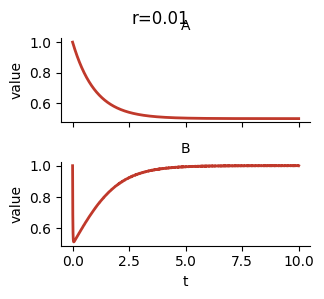

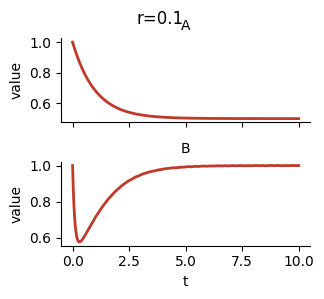

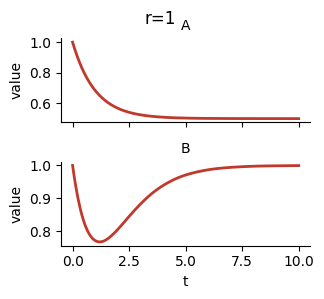

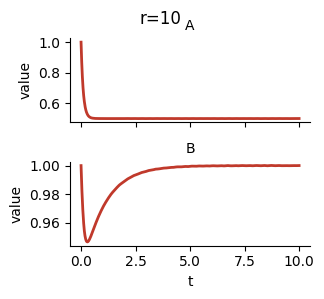

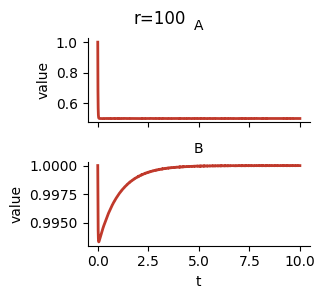

In [32]:
def plot_step_response(tmin, tmax, r, g):

    t_grid = np.linspace(tmin, tmax, 1000)

    state_sol = solve_ivp(lambda t, x: f_state(t=t, x=x, r=r, u_func=const_u), t_span=[tmin, tmax], y0=[A0, B0], t_eval=t_grid)

    sol_df = (
        pd.DataFrame(state_sol.y.T[:,:2], columns=['A', 'B'])
        .assign(t=state_sol.t)
        .melt(id_vars='t', var_name='variable', value_name='value')
    )

    g = sns.relplot(
        data=sol_df, x='t', y='value', row='variable', color='#C0392B', lw=2,
        kind='line', facet_kws={'sharey': False}, legend=False, height=1.5, aspect=2.2
    )
    g.set_titles('{row_name}')

    g.fig.suptitle(f'r={r}')


for r in r_values:
    tmax = 10
    plot_step_response(tmin=0, tmax=tmax, r=r, g=g1(rho=rho, alpha=alpha))

In [33]:

def plot_solution(sol, constant_sol, title):
    t = sol.t
    As = sol.y[0,:]
    Bs = sol.y[1,:]
    Cs = sol.y[2,:]
    lambda_1s = sol.y[3,:]
    lambda_2s = sol.y[4,:]
    us = sol.u

    As_constant = constant_sol.y[0,:]
    Bs_constant = constant_sol.y[1,:]
    Cs_constant = constant_sol.y[2,:]
    us_constant = np.apply_along_axis(arr=t, func1d=const_u, axis=0)

    fig, axs = plt.subplots(nrows=6, ncols=1, figsize=(6,6), sharex=True)

    # some style:
    lw = 2
    optimal_color =   '#C0392B'
    constant_color =  '#A6A6A6'


    ax = axs[0]
    sns.lineplot(x=t, y=As, ax=ax, label='optimal therapy', lw=lw, color=optimal_color)
    sns.lineplot(x=t, y=As_constant, ax=ax, label='constant therapy', lw=lw, color=constant_color)
    ax.set_ylabel('$A$')
    ax.text(t[-1] + 0.02, As[-1], 'optimal', color=optimal_color, va='center', fontsize=8)
    ax.text(t[-1] + 0.02, As_constant[-1], 'constant', color=constant_color, va='center', fontsize=8)

    ax = axs[1]
    sns.lineplot(x=t, y=Bs, ax=ax, label='optimal therapy', lw=lw, color=optimal_color)
    sns.lineplot(x=t, y=Bs_constant, ax=ax, label='constant therapy', lw=lw, color=constant_color)
    ax.set_ylabel('$B$')
    ax.text(t[-1] + 0.02, Bs[-1], 'optimal', color=optimal_color, va='center', fontsize=8)
    ax.text(t[-1] + 0.02, Bs_constant[-1], 'constant', color=constant_color, va='center', fontsize=8)

    ax = axs[2]
    sns.lineplot(x=t, y=Cs, ax=ax, label='optimal therapy', lw=lw, color=optimal_color)
    sns.lineplot(x=t, y=Cs_constant, ax=ax, label='constant therapy', lw=lw, color=constant_color)
    ax.set_ylabel('$\\log C(t) / C(0)$')
    ax.text(t[-1] + 0.02, Cs[-1], 'optimal', color=optimal_color, va='center', fontsize=8)
    ax.text(t[-1] + 0.02, Cs_constant[-1], 'constant', color=constant_color, va='center', fontsize=8)
    # sns.lineplot(x=t, y=np.log2(1 + Cs), ax=ax, label='optimal therapy', lw=lw, color=optimal_color)
    # sns.lineplot(x=t, y=np.log2(1 + Cs_constant), ax=ax, label='constant therapy', lw=lw, color=constant_color)
    # ax.set_ylabel('$\\log 1 + C$')
    # ax.text(t[-1] + 0.02, np.log2(1+Cs[-1]), 'optimal', color=optimal_color, va='center', fontsize=8)
    # ax.text(t[-1] + 0.02, np.log2(1+Cs_constant[-1]), 'constant', color=constant_color, va='center', fontsize=8)

    ax = axs[3]
    sns.lineplot(x=t, y=lambda_1s, ax=ax, lw=lw, color=optimal_color)
    ax.set_ylabel('$\\lambda_1$')

    ax = axs[4]
    sns.lineplot(x=t, y=lambda_2s, ax=ax, lw=lw, color=optimal_color)
    ax.set_ylabel('$\\lambda_2$')

    ax = axs[5]
    sns.lineplot(x=t, y=us, ax=ax, color=optimal_color)
    sns.lineplot(x=t, y=us_constant, ax=ax, color=constant_color)
    ax.set_ylabel('u')
    ax.text(t[-1] + 0.02, us[-1], 'optimal', color=optimal_color, va='center', fontsize=8)
    ax.text(t[-1] + 0.02, us_constant[-1], 'constant', color=constant_color, va='center', fontsize=8)


    for ax in axs:
        sns.despine(ax=ax)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.grid(False)
    
    for ax in axs[0:3]:
        ax.legend().remove()

    fig.suptitle(title)
    plt.show()


from scipy.integrate import trapezoid
from matplotlib.colors import LinearSegmentedColormap


def plot_logfc_C_over_rho_alpha_grid(optimal_sol, g, title):
    t = optimal_sol.t
    tmax = max(t)
    B = optimal_sol.y[1,:]
    f = [g.f(1-_B) for _B in B]
    F = trapezoid(f, t)

    
    alphas = np.logspace(start=-3, stop=3, num=7, base=10)
    rhos = np.logspace(start=-3, stop=3, num=7, base=10)
    log_fcs = np.zeros((len(alphas),len(rhos)))

    for row, alpha in enumerate(alphas):
        for col, rho in enumerate(rhos):
            log_fcs[row, col] = rho*tmax - rho*alpha*F

    fig, ax = plt.subplots(figsize=(4,4))
    cmap = LinearSegmentedColormap.from_list('green_white', ["#28ca69", 'white'])
    sns.heatmap(log_fcs, ax=ax, cmap=cmap, vmin=-10, vmax=0,
                cbar_kws={'label': 'C log fold-change \n(truncated at 0)', 'extend': 'min'})
    ax.invert_yaxis()  # α increases upward
    ax.set_xlabel('ρ')
    ax.set_ylabel('α')

    ax.set_xticklabels([f'$10^{{{i}}}$' for i in np.arange(-3,4)])
    ax.set_yticklabels([f'$10^{{{i}}}$' for i in np.arange(-3,4)])

    fig.suptitle(title)
    return 

converged after 1157 iterations


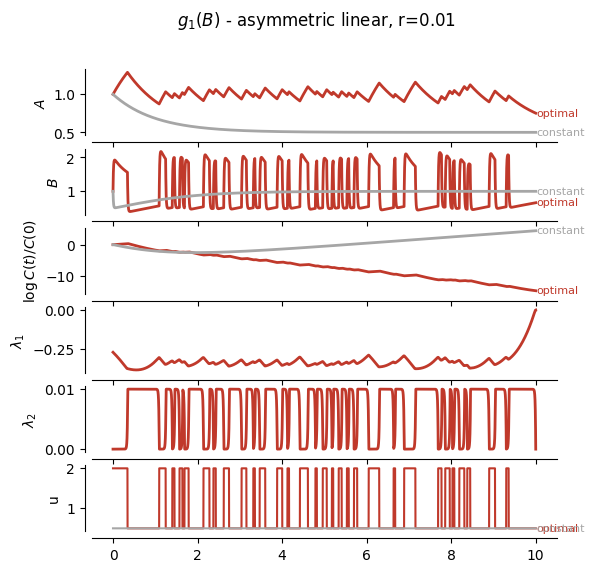

converged after 300 iterations


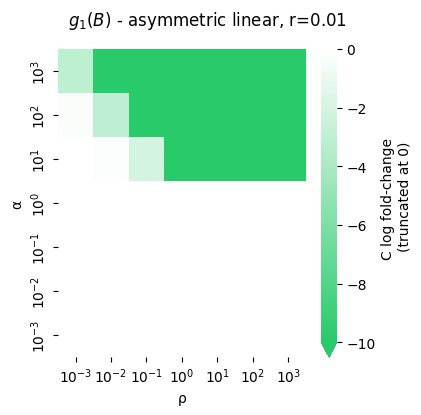

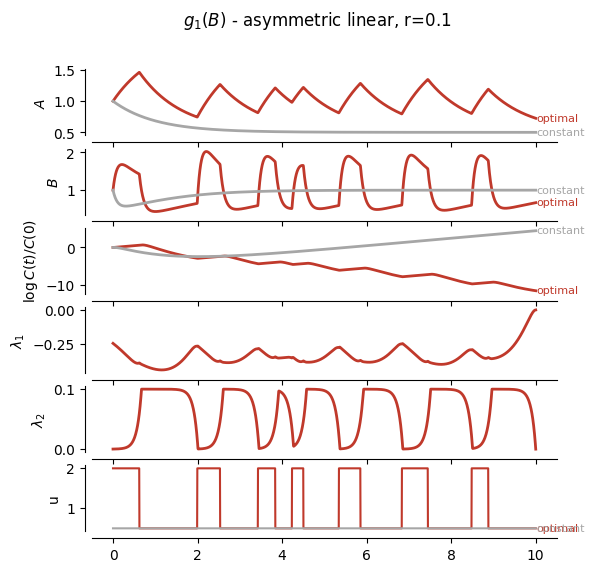

converged after 76 iterations


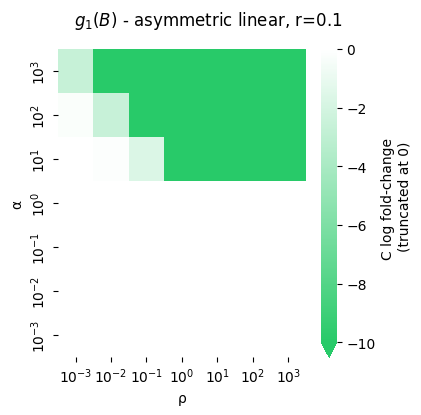

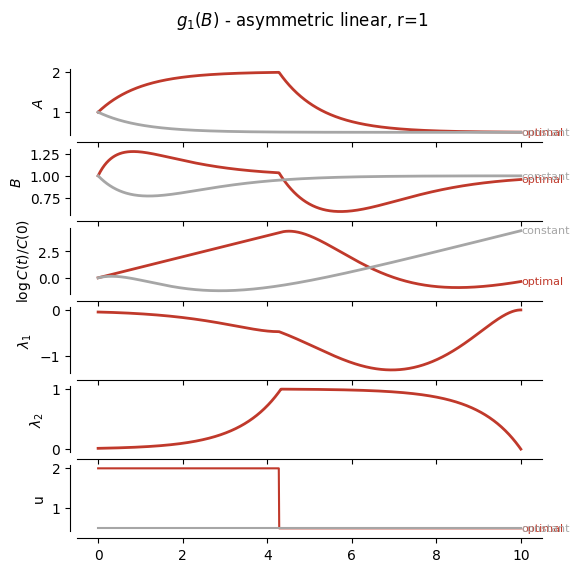

NOT converged after 3000 iterations


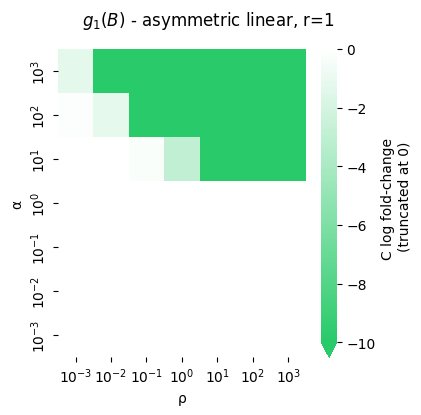

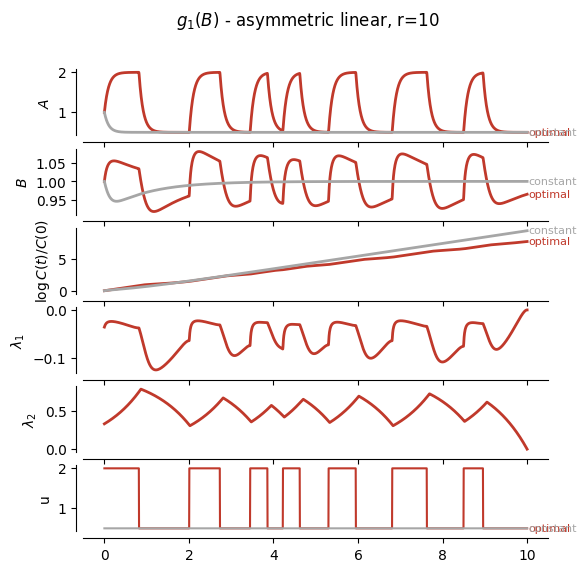

converged after 1392 iterations


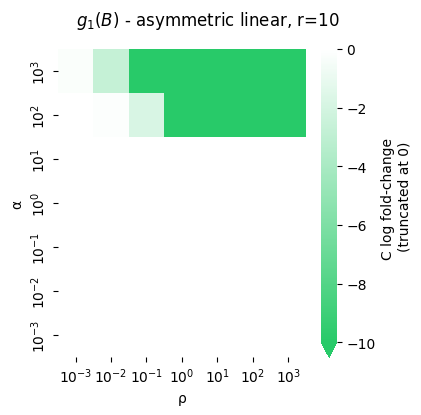

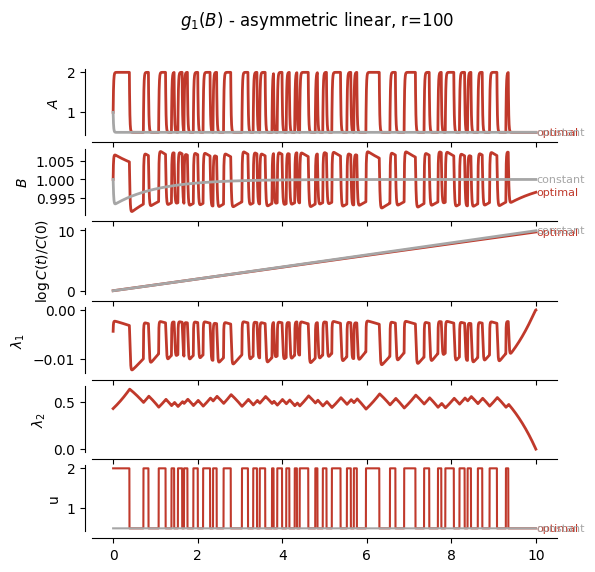

converged after 5 iterations


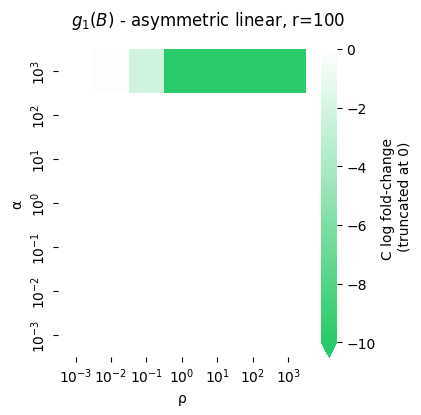

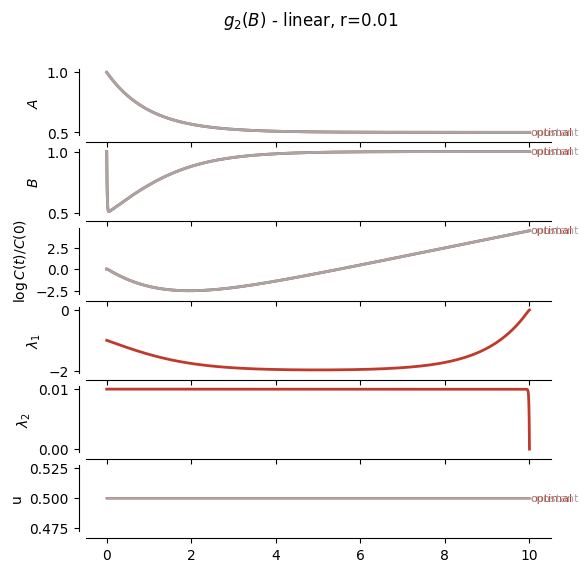

converged after 5 iterations


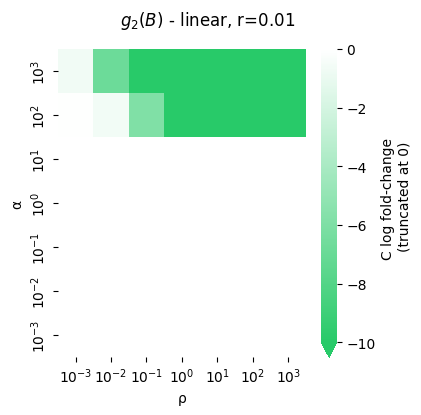

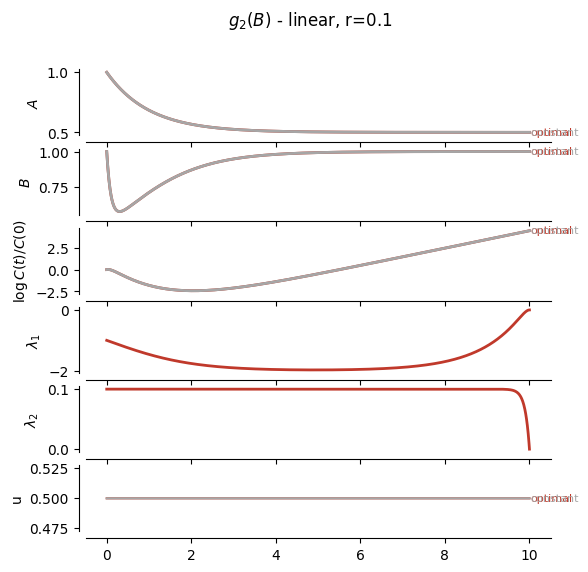

converged after 5 iterations


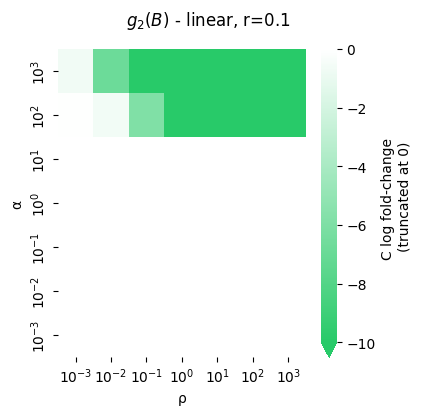

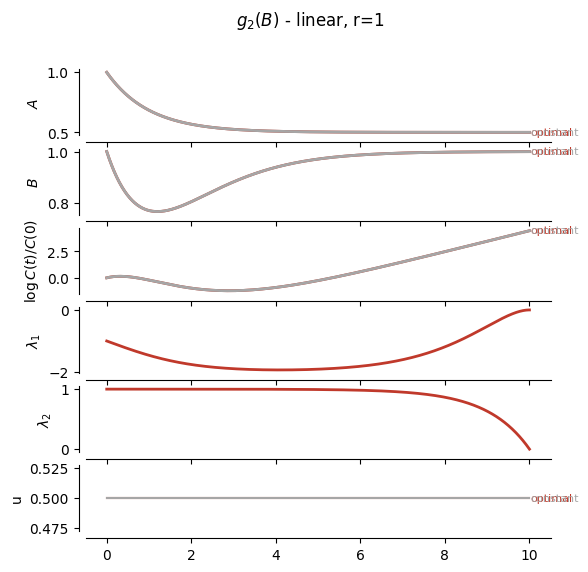

converged after 5 iterations


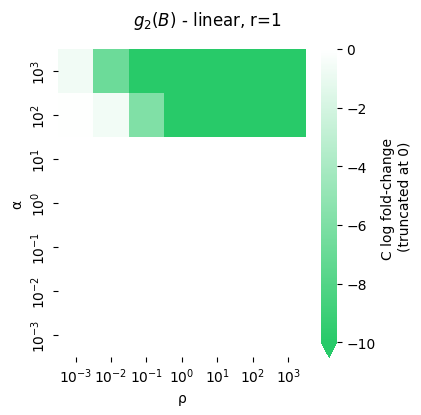

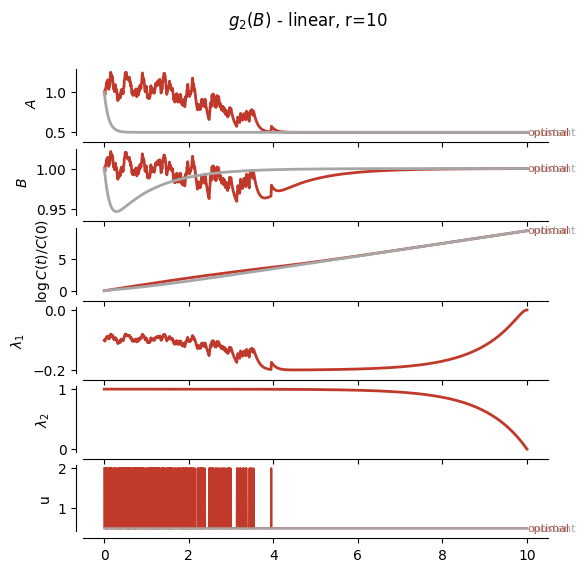

converged after 5 iterations


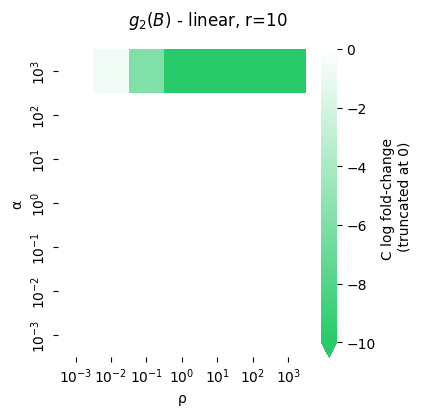

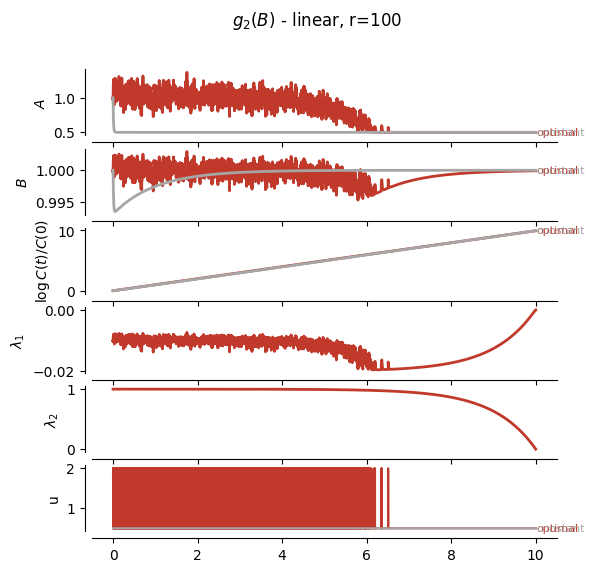

converged after 1321 iterations


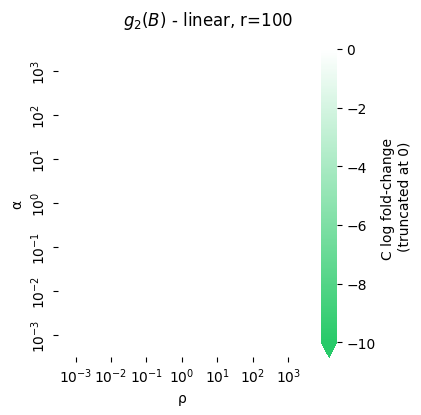

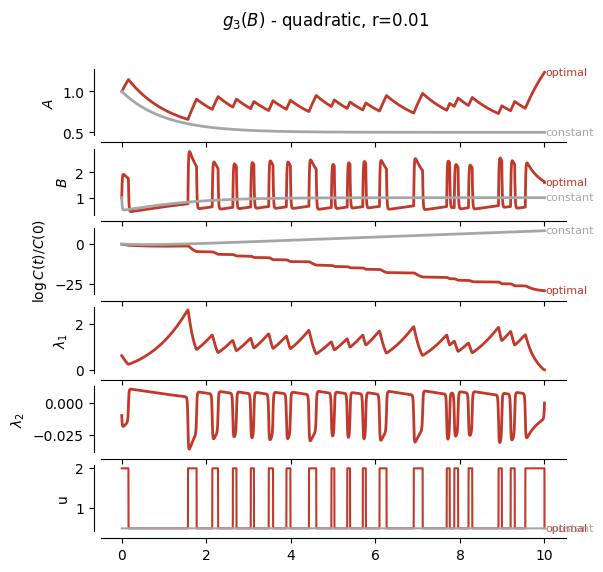

converged after 233 iterations


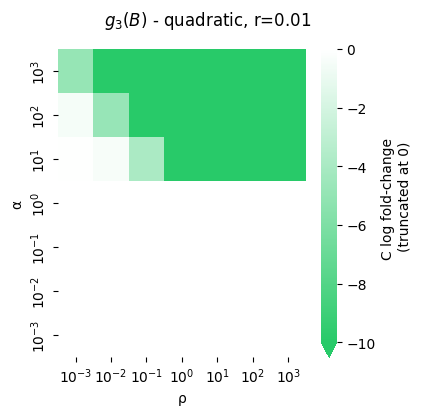

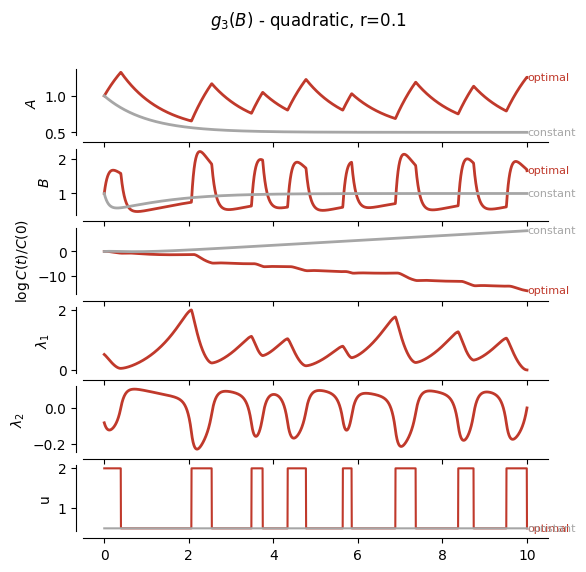

converged after 216 iterations


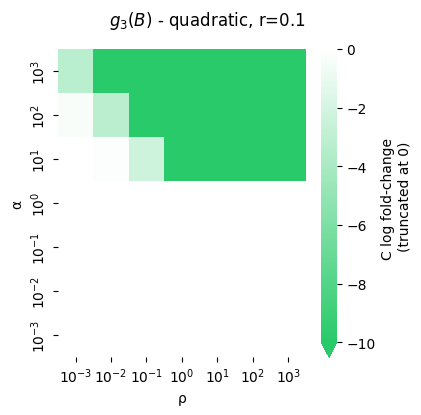

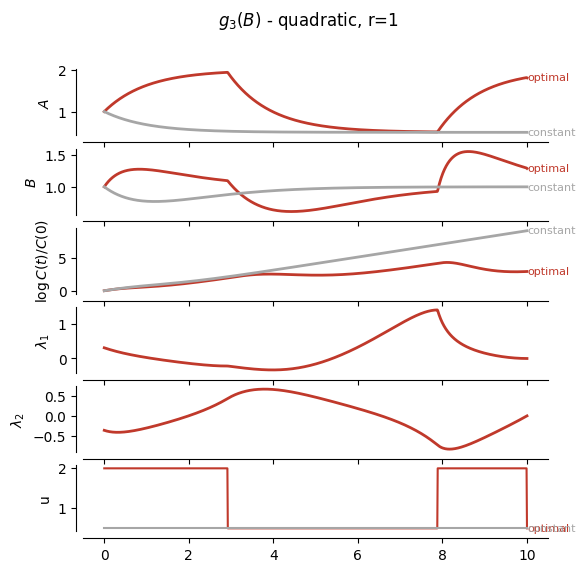

converged after 237 iterations


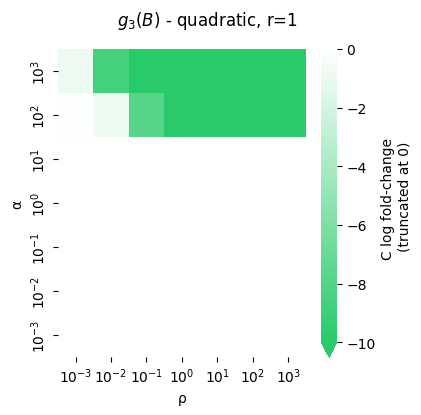

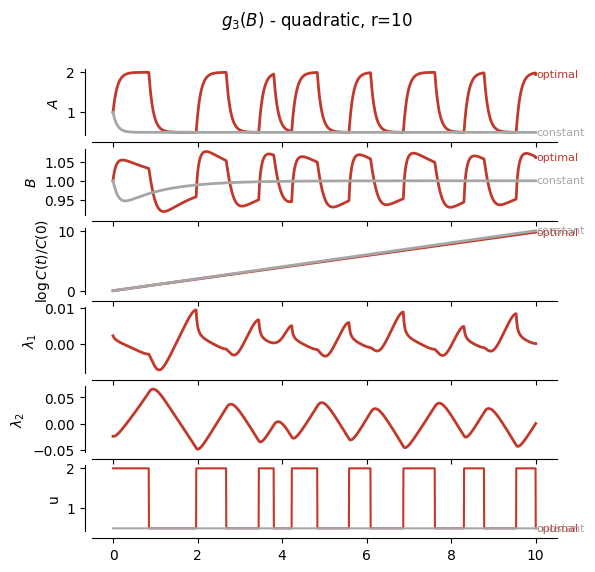

converged after 1259 iterations


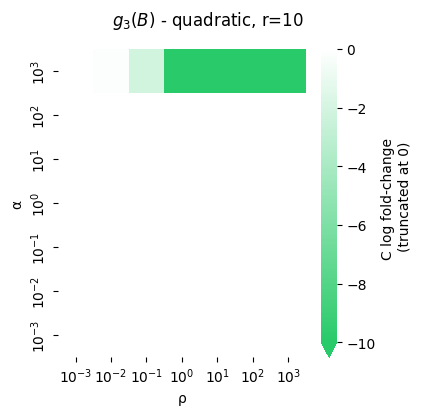

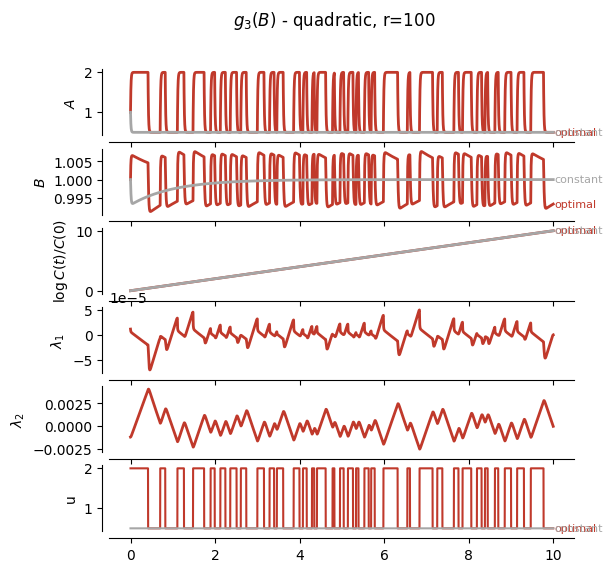

NOT converged after 3000 iterations


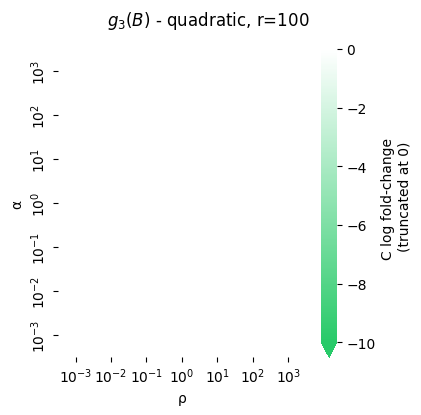

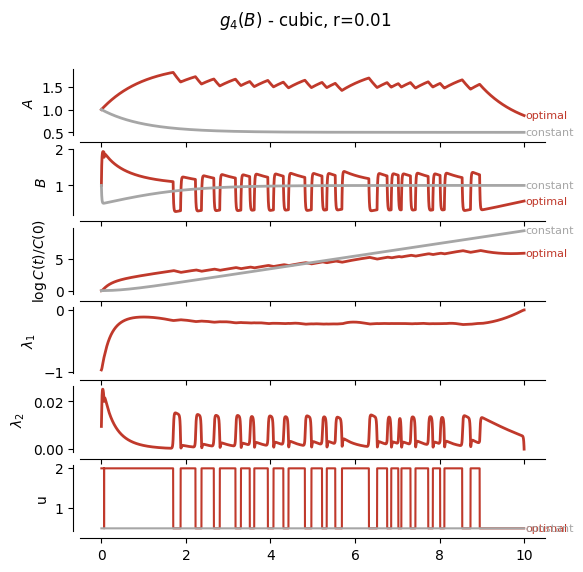

NOT converged after 3000 iterations


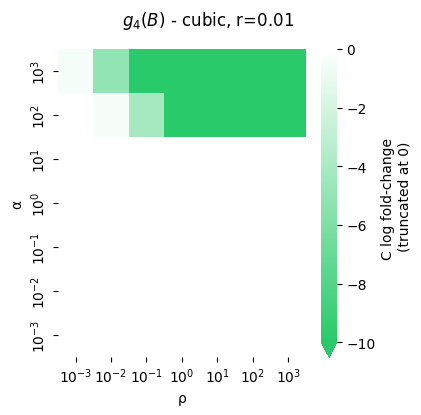

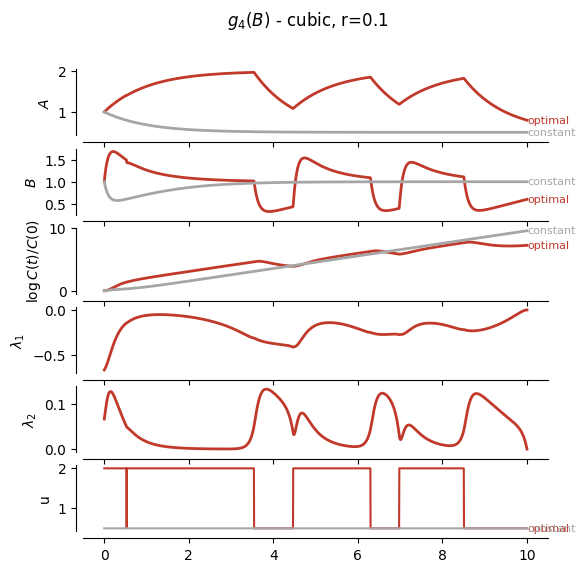

NOT converged after 3000 iterations


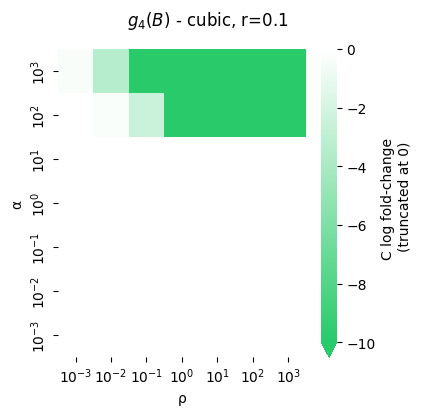

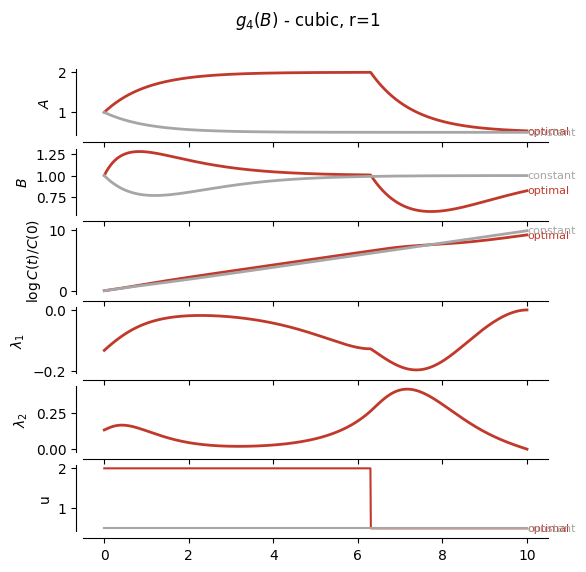

NOT converged after 3000 iterations


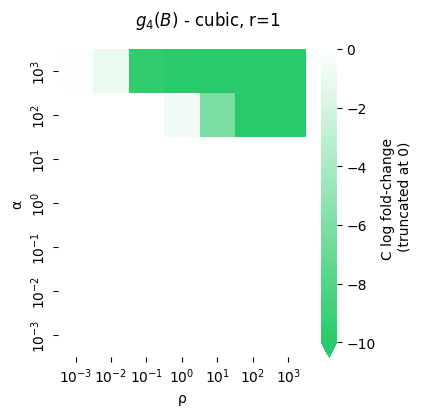

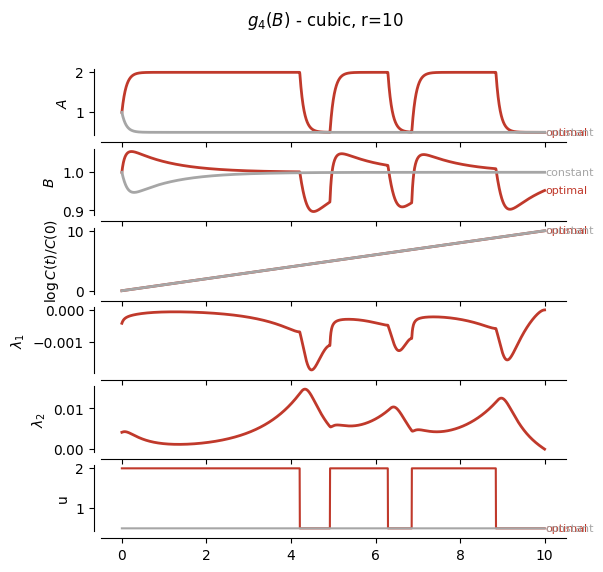

NOT converged after 3000 iterations


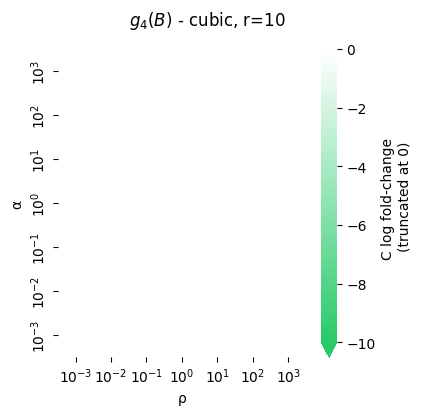

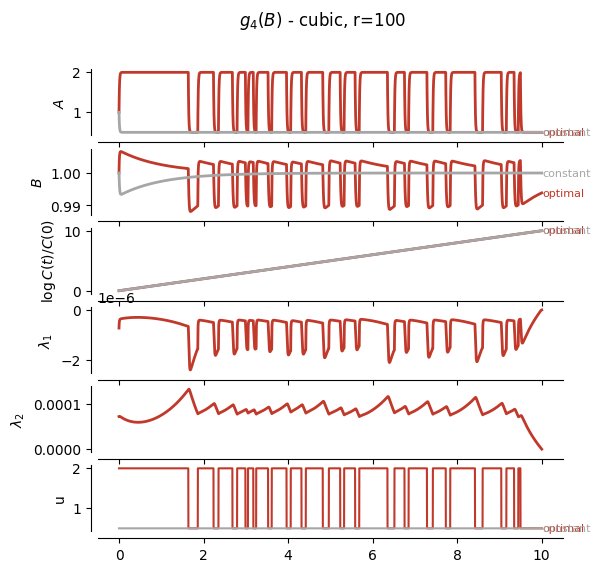

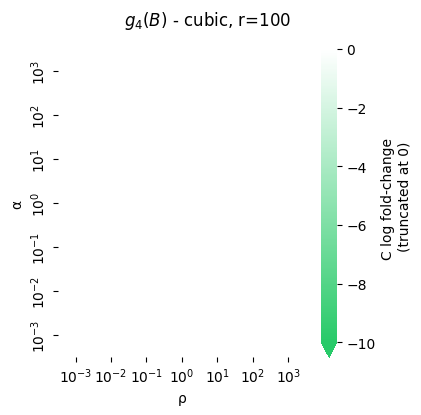

In [34]:
_rho = 1
_alpha = 2**3

for _g in [g1, g2, g3, g4]:
    g = _g(rho=_rho, alpha=_alpha)
    display(g)
    for r in r_values:
        
        tmin = 0
        tmax = 10

        # resolve the fast variable: its time constant is 1/max(r, 1/r)
        t_grid_n = max(int(20*max(r, 1/r)*tmax) + 1, 1000)
        t_grid = np.linspace(tmin, tmax, t_grid_n)

        optimal_sol = forward_backward_optimal_solution(tmin, tmax, t_grid_n, r, g)
        constant_sol = get_constant_solution(tmin, tmax,t_grid,r,g)

        plot_solution(optimal_sol, constant_sol, title=f'{g}, r={r}')
        plot_logfc_C_over_rho_alpha_grid(optimal_sol, g, title=f'{g}, r={r}')